Import Library

In [1]:
# ==============================================================================
# CELL 1: IMPORT LIBRARY
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Pengaturan visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✓ Library berhasil di-import!")

✓ Library berhasil di-import!


Unggah File Dataset ke Google Colab

In [2]:
# ==============================================================================
# CELL 2: UPLOAD & BACA DATASET SECARA AMAN
# ==============================================================================
print("Silakan upload file dataset Anda (format .xlsx atau .csv):")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

def baca_data_aman(nama_file):
    """Mendeteksi letak baris header sebenarnya agar tidak terhalang judul bulan"""
    if nama_file.endswith('.csv'):
        with open(nama_file, 'r', encoding='utf-8', errors='ignore') as f:
            lines = f.readlines()
        baris_header = 0
        for i, baris in enumerate(lines[:15]):
            if 'MR Date' in baris and 'Tgl Penyerahan' in baris:
                baris_header = i
                break
        df = pd.read_csv(nama_file, skiprows=baris_header, on_bad_lines='skip')
    else:
        # Jika file Excel (.xlsx / .xls)
        df_temp = pd.read_excel(nama_file, header=None)
        baris_header = 0
        for i in range(min(15, len(df_temp))):
            baris_isi = df_temp.iloc[i].astype(str).tolist()
            if any('MR Date' in val for val in baris_isi):
                baris_header = i
                break
        df = pd.read_excel(nama_file, skiprows=baris_header)

    return df

df_raw = baca_data_aman(file_name)
df_raw.columns = df_raw.columns.astype(str).str.strip()
print(f"✓ File '{file_name}' berhasil dibaca!")
df_raw.head()

Silakan upload file dataset Anda (format .xlsx atau .csv):


Saving DES 2025- JULI 2026_EJP.xlsx to DES 2025- JULI 2026_EJP.xlsx
✓ File 'DES 2025- JULI 2026_EJP.xlsx' berhasil dibaca!


,NO,Part ID,Description,Qty,Unit,WO Date,WO No.,MR Date,MR No.,Tgl Penyerahan,No. Penyerahan,Status
0,1,44-FG27,"POWER CABLE, FLAT AWG#2, GALVANIZED",1,REEL,2025-12-01 00:00:00,WO/DR/2025/12/0002,2025-12-02 00:00:00,MR-P/DR-A/2025/12/0008,2025-12-02 00:00:00,DN-M/DR/2025/12/0012,CLOSED
1,2,44-FG27,"POWER CABLE, FLAT AWG#2, GALVANIZED",1,REEL,2025-12-01 00:00:00,WO/DR/2025/12/0003,2025-12-01 00:00:00,MR-P/DR-A/2025/12/0006,2025-12-02 00:00:00,DN-M/DR/2025/12/0013,CLOSED
2,3,44-FG17,"POWER CABLE, FLAT AWG#1, GALVANIZED",1,REEL,2025-12-01 00:00:00,WO/DR/2025/12/0004,2025-12-02 00:00:00,MR-P/DR-A/2025/12/0019,2025-12-02 00:00:00,DN-M/DR/2025/12/0026,CLOSED
3,NaN,NaN,NaN,NaN,NaN,NaN,WO/DR/2025/12/0004,2025-12-02 00:00:00,MR-P/DR-A/2025/12/0019,2025-12-02 00:00:00,DN-M/DR/2025/12/0026,CLOSED
4,4,44-FG27,"POWER CABLE, FLAT AWG#2, GALVANIZED",1,REEL,2025-12-01 00:00:00,WO/DR/2025/12/0005,2025-12-02 00:00:00,MR-P/DR-A/2025/12/0007,2025-12-02 00:00:00,DN-M/DR/2025/12/0014,CLOSED


Statistik Deskriptif

In [3]:
import numpy as np
import pandas as pd

# 1. Baca file Excel
# Parameter header=1 dipakai karena baris pertama file berisi label bulan,
# sedangkan nama kolom asli (NO, Part ID, dll.) ada di baris kedua.
file_name = "DES 2025- JULI 2026_EJP.xlsx"
df = pd.read_excel(file_name, header=1)

# 2. Ringkasan Statistik Deskriptif Kolom (Persis seperti tabel awal kamu)
ringkasan_umum = df.describe()
print("=== RINGKASAN DESKRIPTIF DATASET AWAL ===")
print(ringkasan_umum)

# Format transpose agar lebih rapi saat dibaca / diekspor ke LaTeX
ringkasan_transpose = ringkasan_umum.transpose()
print("\n=== RINGKASAN FORMAT TRANSPOSE ===")
print(ringkasan_transpose)

# 3. Data Cleaning: Buang baris header yang terselip di tengah tabel
df_clean = df[df["WO Date"] != "WO Date"].copy()

# Konversi kolom tanggal ke tipe datetime
kolom_tanggal = ["WO Date", "MR Date", "Tgl Penyerahan"]
for col in kolom_tanggal:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# 4. Hitung Durasi Pemenuhan Material (Tgl Penyerahan - MR Date) dalam satuan Hari
df_clean["Durasi_Hari"] = (
    df_clean["Tgl Penyerahan"] - df_clean["MR Date"]
).dt.days
durasi = df_clean["Durasi_Hari"].dropna()

# 5. Hitung Parameter Statistik Deskriptif Durasi
q1 = durasi.quantile(0.25)
q2 = durasi.median()
q3 = durasi.quantile(0.75)
iqr = q3 - q1
batas_atas = q3 + (1.5 * iqr)
durasi_min = durasi.min()
durasi_max = durasi.max()

tabel_durasi = pd.DataFrame(
    {
        "Parameter Statistik": [
            "Kuartil Pertama ($Q_1$)",
            "Median / Kuartil Kedua ($Q_2$)",
            "Kuartil Ketiga ($Q_3$)",
            "Jangkauan Antarkuartil ($IQR$)",
            r"Batas Atas Matematis ($Q_3 + 1{,}5 \times IQR$)",
            "Durasi Minimum",
            "Durasi Maksimum Awal",
        ],
        "Nilai Empiris (Hari)": [
            f"{q1:.2f}",
            f"{q2:.2f}",
            f"{q3:.2f}",
            f"{iqr:.2f}",
            f"{batas_atas:.2f}",
            f"{durasi_min:.2f}",
            f"{durasi_max:.2f}",
        ],
    }
)

print("\n=== STATISTIK SEBARAN DURASI PEMENUHAN ===")
print(tabel_durasi.to_string(index=False))

# 6. Ekspor Otomatis ke Sintaks Tabel LaTeX
print("\n=== SINTAKS LATEX TABEL DURASI ===")
print(
    tabel_durasi.to_latex(
        index=False,
        caption="Statistik Deskriptif Sebaran Durasi Pemenuhan Material",
        label="tab:statistik_durasi",
        escape=False,
    )
)

=== RINGKASAN DESKRIPTIF DATASET AWAL ===
         NO  Part ID                          Description  Qty  Unit  \
count   939      925                                  924  928   928   
unique  187      115                                  115    2     4   
top       1  44-FG27  POWER CABLE, FLAT AWG#2, GALVANIZED    1  UNIT   
freq      7       91                                   91  922   702   

                    WO Date              WO No.              MR Date  \
count                   930                1316                 1310   
unique                   95                 927                  127   
top     2025-12-03 00:00:00  WO/DR/2026/04/0175  2026-05-04 00:00:00   
freq                     40                   8                   39   

                        MR No.       Tgl Penyerahan  No. Penyerahan  Status  
count                     1310                 1300            1300    1316  
unique                     971                  123            1050       8  
to

Data Cleaning (Pembersihan Data)

In [4]:
# ==============================================================================
# CELL 3: PEMBERSIHAN DATA (DATA CLEANING)
# ==============================================================================
df = df_raw.copy()

# 1. Hapus baris header berulang di tengah tabel
df = df[df['MR Date'] != 'MR Date']
df = df.dropna(subset=['MR Date'])
df = df[df['MR Date'].astype(str).str.contains('-', na=False)]

# 2. Forward fill untuk mengisi sel hasil merge yang kosong
kolom_ffill = ['Part ID', 'Description', 'Qty', 'Unit', 'WO Date', 'WO No.']
for kol in kolom_ffill:
    if kol in df.columns:
        df[kol] = df[kol].replace('', np.nan).ffill()

# 3. Hapus data yang belum diserahkan (status PENDING atau tanpa tanggal)
df = df.dropna(subset=['Tgl Penyerahan'])
df = df[df['Tgl Penyerahan'].astype(str).str.contains('-', na=False)]

# 4. Konversi format tanggal ke Datetime
df['MR Date'] = pd.to_datetime(df['MR Date'], errors='coerce')
df['Tgl Penyerahan'] = pd.to_datetime(df['Tgl Penyerahan'], errors='coerce')
df['WO Date'] = pd.to_datetime(df['WO Date'], errors='coerce')

# Hapus baris jika ada parsing tanggal yang gagal
df = df.dropna(subset=['MR Date', 'Tgl Penyerahan']).reset_index(drop=True)

print(f"✓ Pembersihan selesai! Jumlah baris data valid: {len(df)}")
df[['Part ID', 'Description', 'MR Date', 'Tgl Penyerahan', 'Status']].head()

✓ Pembersihan selesai! Jumlah baris data valid: 1294


/tmp/ipykernel_692/2845500022.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[kol] = df[kol].replace('', np.nan).ffill()


,Part ID,Description,MR Date,Tgl Penyerahan,Status
0,44-FG27,"POWER CABLE, FLAT AWG#2, GALVANIZED",2025-12-02,2025-12-02,CLOSED
1,44-FG27,"POWER CABLE, FLAT AWG#2, GALVANIZED",2025-12-01,2025-12-02,CLOSED
2,44-FG17,"POWER CABLE, FLAT AWG#1, GALVANIZED",2025-12-02,2025-12-02,CLOSED
3,44-FG17,"POWER CABLE, FLAT AWG#1, GALVANIZED",2025-12-02,2025-12-02,CLOSED
4,44-FG27,"POWER CABLE, FLAT AWG#2, GALVANIZED",2025-12-02,2025-12-02,CLOSED


Pelabelan Target & Rekayasa Fitur (Feature Engineering)

In [5]:
# ==============================================================================
# CELL 4: PELABELAN TARGET & REKAYASA FITUR
# ==============================================================================

# 1. Hitung durasi pemenuhan (Hari)
df['Durasi_Hari'] = (df['Tgl Penyerahan'] - df['MR Date']).dt.days
df = df[df['Durasi_Hari'] >= 0].copy()

# 2. Pelabelan 3 Kategori
def tentukan_kategori(hari):
    if hari <= 1:
        return 'Cepat'
    elif hari <= 3:
        return 'Standar'
    else:
        return 'Lambat'

df['Kategori'] = df['Durasi_Hari'].apply(tentukan_kategori)

# 3. Rekayasa Fitur Masukan (Input Features)
# - Ekstraksi jenis material dari deskripsi
def ekstrak_material(desc):
    desc = str(desc).upper()
    if 'PUMP' in desc: return 'PUMP'
    if 'MOTOR' in desc: return 'MOTOR'
    if 'CABLE' in desc: return 'CABLE'
    if 'PROTECTOR' in desc: return 'PROTECTOR'
    if 'INTAKE' in desc or 'INI' in desc: return 'INTAKE'
    if 'AGH' in desc: return 'AGH'
    if 'FCE' in desc: return 'FCE'
    return 'OTHER'

df['Jenis_Material'] = df['Description'].apply(ekstrak_material)
df['Qty'] = pd.to_numeric(df['Qty'], errors='coerce').fillna(1)
df['Unit'] = df['Unit'].astype(str).str.strip().str.upper()

# - Fitur waktu permintaan
df['Gap_WO_MR'] = (df['MR Date'] - df['WO Date']).dt.days.fillna(0).clip(lower=0)
df['MR_DayOfWeek'] = df['MR Date'].dt.dayofweek  # 0=Senin, 6=Minggu
df['MR_Month'] = df['MR Date'].dt.month

print("="*45)
print("DISTRIBUSI DATA KELAS TARGET (IMBALANCE DATA):")
print("="*45)
print(df['Kategori'].value_counts())
print("\nPersentase:")
print(df['Kategori'].value_counts(normalize=True) * 100)

DISTRIBUSI DATA KELAS TARGET (IMBALANCE DATA):
Kategori
Cepat      1006
Standar     186
Lambat      102
Name: count, dtype: int64

Persentase:
Kategori
Cepat      77.743431
Standar    14.374034
Lambat      7.882535
Name: proportion, dtype: float64


Deteksi & Penanganan Outlier (Metode IQR)

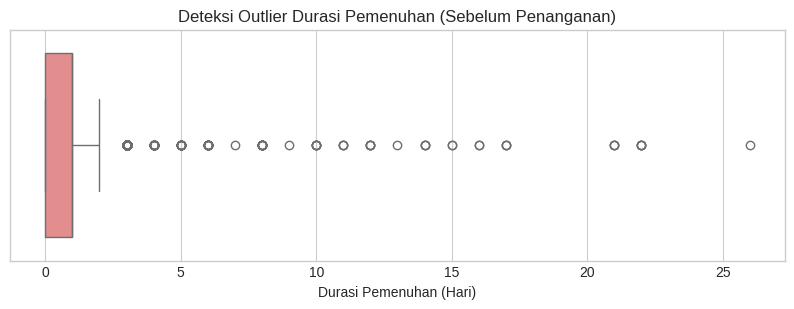

Nilai Q1: 0.0 hari | Nilai Q3: 1.0 hari | IQR: 1.0
Batas Atas Matematis (Q3 + 1.5*IQR): 2.5 hari

Ditemukan 0 data outlier ekstrem (typo penanggalan tahun):


,Part ID,MR Date,Tgl Penyerahan,Durasi_Hari


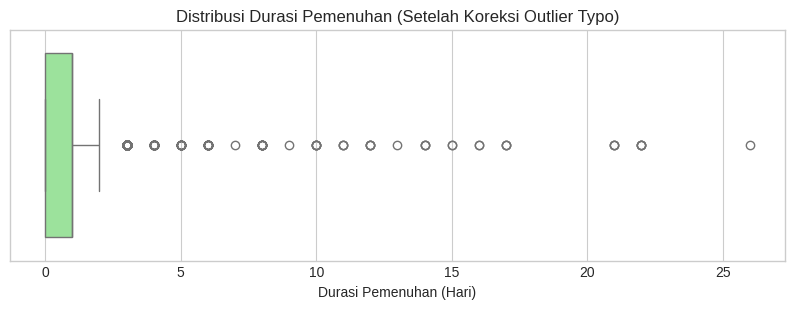

✓ Data setelah penanganan outlier: 1294 baris


In [6]:
# ==============================================================================
# DETEKSI & PENANGANAN OUTLIER (METODE IQR - INTERQUARTILE RANGE)
# ==============================================================================

# 1. Visualisasi Boxplot Sebelum Pembersihan Outlier
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['Durasi_Hari'], color='lightcoral')
plt.title('Deteksi Outlier Durasi Pemenuhan (Sebelum Penanganan)')
plt.xlabel('Durasi Pemenuhan (Hari)')
plt.show()

# 2. Perhitungan Batas IQR
Q1 = df['Durasi_Hari'].quantile(0.25)
Q3 = df['Durasi_Hari'].quantile(0.75)
IQR = Q3 - Q1

# Batas atas wajar secara operasional (misal maksimum 30 hari untuk batas wajar gudang)
# atau menggunakan batas matematis IQR:
batas_atas_iqr = Q3 + (1.5 * IQR)

print(f"Nilai Q1: {Q1} hari | Nilai Q3: {Q3} hari | IQR: {IQR}")
print(f"Batas Atas Matematis (Q3 + 1.5*IQR): {batas_atas_iqr:.1f} hari")

# 3. Identifikasi Data Outlier Ekstrem (Typo seperti durasi > 30 hari atau 366 hari)
outlier_ekstrem = df[df['Durasi_Hari'] > 30]
print(f"\nDitemukan {len(outlier_ekstrem)} data outlier ekstrem (typo penanggalan tahun):")
display(outlier_ekstrem[['Part ID', 'MR Date', 'Tgl Penyerahan', 'Durasi_Hari']])

# 4. Penanganan Outlier (Koreksi atau Filter):
# Hapus outlier typo yang tidak masuk akal (misal > 60 hari karena salah tahun)
df_clean = df[df['Durasi_Hari'] <= 30].copy()

# Visualisasi Setelah Outlier Ekstrem Ditangani
plt.figure(figsize=(10, 3))
sns.boxplot(x=df_clean['Durasi_Hari'], color='lightgreen')
plt.title('Distribusi Durasi Pemenuhan (Setelah Koreksi Outlier Typo)')
plt.xlabel('Durasi Pemenuhan (Hari)')
plt.show()

print(f"✓ Data setelah penanganan outlier: {len(df_clean)} baris")

Visualisasi Eksplorasi Data (EDA)

/tmp/ipykernel_692/4203861113.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Kategori', order=['Cepat', 'Standar', 'Lambat'], palette='Blues_r')


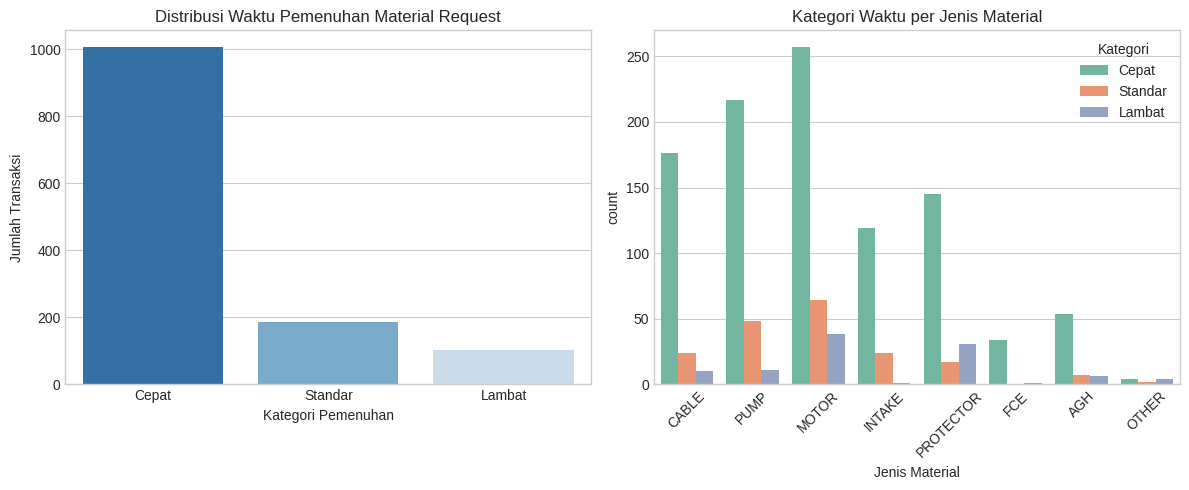

In [7]:
# ==============================================================================
# CELL 5: VISUALISASI EKSPLORASI DATA
# ==============================================================================
plt.figure(figsize=(12, 5))

# Plot 1: Distribusi Target
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Kategori', order=['Cepat', 'Standar', 'Lambat'], palette='Blues_r')
plt.title('Distribusi Waktu Pemenuhan Material Request')
plt.xlabel('Kategori Pemenuhan')
plt.ylabel('Jumlah Transaksi')

# Plot 2: Kategori Waktu per Jenis Material
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Jenis_Material', hue='Kategori', hue_order=['Cepat', 'Standar', 'Lambat'], palette='Set2')
plt.title('Kategori Waktu per Jenis Material')
plt.xlabel('Jenis Material')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Persiapan Data & Pembagian (Train-Test Split)

In [8]:
# ==============================================================================
# CELL 6: DATA ENCODING & SPLIT DATA
# ==============================================================================
# Fitur Masukan (X) dan Target (y)
fitur_input = ['Jenis_Material', 'Unit', 'Qty', 'Gap_WO_MR', 'MR_DayOfWeek', 'MR_Month']
X = df[fitur_input]
y = df['Kategori']

# One-Hot Encoding fitur kategorikal
X_encoded = pd.get_dummies(X, columns=['Jenis_Material', 'Unit'], drop_first=True)

# Split Dataset: 80% Latih (Train) & 20% Uji (Test)
# Gunakan stratify=y agar proporsi kelas Cepat, Standar, Lambat tetap terjaga
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✓ Data Latih (Train) : {X_train.shape[0]} baris")
print(f"✓ Data Uji (Test)   : {X_test.shape[0]} baris")

✓ Data Latih (Train) : 1035 baris
✓ Data Uji (Test)   : 259 baris


Pelatihan Model Random Forest (Mencegah Overfitting & Imbalance)

In [9]:
# ==============================================================================
# CELL 7: TRAINING RANDOM FOREST CLASSIFIER
# ==============================================================================
rf_model = RandomForestClassifier(
    n_estimators=100,         # 100 pohon keputusan acak
    max_depth=6,              # PEMBATAS KEDALAMAN: Mencegah Overfitting
    min_samples_leaf=2,       # Minimal 2 data di daun keputusan (mencegah hafalan)
    class_weight='balanced',  # SOLUSI IMBALANCE DATA: Memberi bobot ekstra pada Standar & Lambat
    random_state=42
)

# Latih model
rf_model.fit(X_train, y_train)
print("✓ Model Random Forest Berhasil Dilatih!")

✓ Model Random Forest Berhasil Dilatih!


Evaluasi & Uji Overfitting (Train vs Test Accuracy)

AKURASI TRAINING (DATA LATIH) : 80.00%
AKURASI TESTING  (DATA UJI)   : 74.52%
SELISIH / GAP (OVERFITTING)   : 5.48%
KESIMPULAN: Terdapat indikasi perbedaan performa data latih dan uji.

=== CLASSIFICATION REPORT (DATA UJI) ===
              precision    recall  f1-score   support

       Cepat       0.94      0.76      0.84       201
      Lambat       0.30      0.62      0.40        21
     Standar       0.52      0.73      0.61        37

    accuracy                           0.75       259
   macro avg       0.58      0.70      0.62       259
weighted avg       0.83      0.75      0.77       259



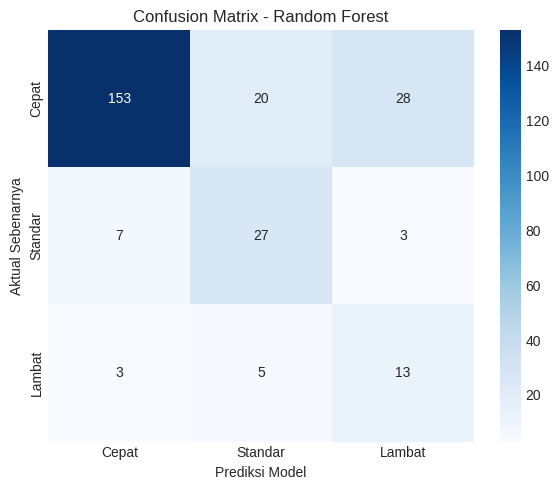

In [10]:
# ==============================================================================
# CELL 8: EVALUASI PERFORMA & CEK OVERFITTING
# ==============================================================================
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print("="*50)
print(f"AKURASI TRAINING (DATA LATIH) : {acc_train * 100:.2f}%")
print(f"AKURASI TESTING  (DATA UJI)   : {acc_test * 100:.2f}%")
print(f"SELISIH / GAP (OVERFITTING)   : {abs(acc_train - acc_test) * 100:.2f}%")
print("="*50)

if abs(acc_train - acc_test) <= 0.05:
    print("KESIMPULAN: Model SANGAT BAGUS (Tidak Terjadi Overfitting, selisih <= 5%)\n")
else:
    print("KESIMPULAN: Terdapat indikasi perbedaan performa data latih dan uji.\n")

# Classification Report
print("=== CLASSIFICATION REPORT (DATA UJI) ===")
print(classification_report(y_test, y_pred_test))

# Confusion Matrix
label_urutan = ['Cepat', 'Standar', 'Lambat']
cm = confusion_matrix(y_test, y_pred_test, labels=label_urutan)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_urutan, yticklabels=label_urutan)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual Sebenarnya')
plt.tight_layout()
plt.show()

Analisis Fitur Paling Berpengaruh (Feature Importance)

/tmp/ipykernel_692/948811838.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values[:10], y=importances.index[:10], palette='viridis')


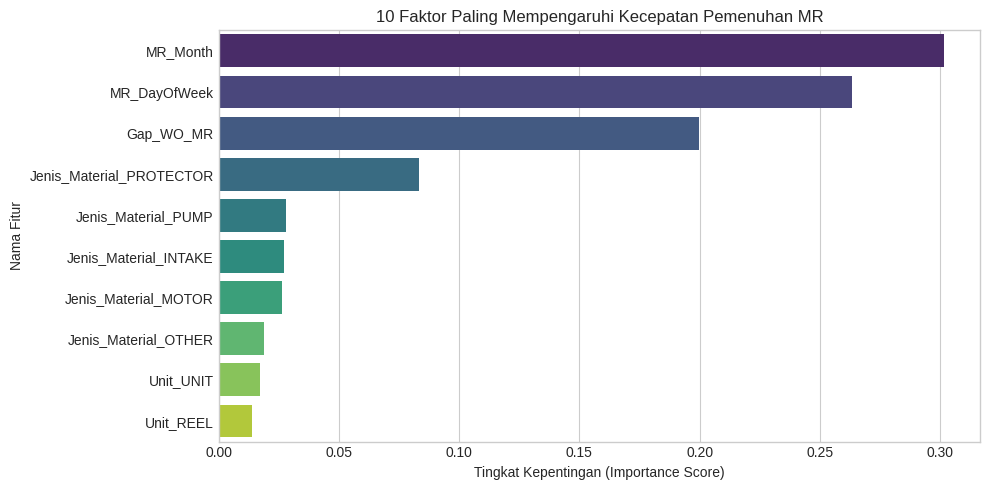

In [11]:
# ==============================================================================
# CELL 9: FEATURE IMPORTANCE
# ==============================================================================
importances = pd.Series(rf_model.feature_importances_, index=X_encoded.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values[:10], y=importances.index[:10], palette='viridis')
plt.title('10 Faktor Paling Mempengaruhi Kecepatan Pemenuhan MR')
plt.xlabel('Tingkat Kepentingan (Importance Score)')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

Uji Coba Prediksi Permintaan Baru (Simulasi Lapangan)

In [12]:
# ==============================================================================
# CELL 10: SIMULASI PREDIKSI MATERIAL BARU
# ==============================================================================
def prediksi_mr_baru(jenis_material, unit, qty, gap_wo_mr, hari_ke, bulan):
    data_baru = pd.DataFrame([{
        'Jenis_Material': jenis_material,
        'Unit': unit,
        'Qty': qty,
        'Gap_WO_MR': gap_wo_mr,
        'MR_DayOfWeek': hari_ke,
        'MR_Month': bulan
    }])

    # Samakan kolom dengan data training
    data_baru_encoded = pd.get_dummies(data_baru, columns=['Jenis_Material', 'Unit'])
    data_baru_encoded = data_baru_encoded.reindex(columns=X_encoded.columns, fill_value=0)

    hasil_pred = rf_model.predict(data_baru_encoded)[0]
    peluang = rf_model.predict_proba(data_baru_encoded)[0]

    print("="*45)
    print(f"Material Diajukan: {jenis_material} ({qty} {unit})")
    print(f"Prediksi Waktu   : {hasil_pred.upper()}")
    for idx, cls in enumerate(rf_model.classes_):
        print(f" - Peluang {cls:<7}: {peluang[idx]*100:.1f}%")
    print("="*45)

# Contoh simulasi: Pengajuan Pompa (PUMP) sebanyak 1 Unit
prediksi_mr_baru(jenis_material='PUMP', unit='UNIT', qty=1, gap_wo_mr=1, hari_ke=1, bulan=7)

Material Diajukan: PUMP (1 UNIT)
Prediksi Waktu   : CEPAT
 - Peluang Cepat  : 54.1%
 - Peluang Lambat : 14.8%
 - Peluang Standar: 31.2%


In [14]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- KONFIGURASI HALAMAN ---
st.set_page_config(
    page_title="Dashboard Prediksi Material Request - PT EJP",
    page_icon="📦",
    layout="wide"
)

# --- JUDUL UTAMA ---
st.title("📦 Dashboard Monitoring & Klasifikasi Waktu Pemenuhan Material Request")
st.markdown("**PT Epsindo Jaya Pratama (EJP) Workshop Duri** | Studi Kasus Algoritma *Random Forest*")
st.markdown("---")

# --- CACHE DATA & MODEL ---
@st.cache_resource
def load_and_train_model():
    file_name = "DES 2025- JULI 2026_EJP.xlsx"
    try:
        df_temp = pd.read_excel(file_name, header=None)
        baris_header = 0
        for i in range(min(15, len(df_temp))):
            baris_isi = df_temp.iloc[i].astype(str).tolist()
            if any('MR Date' in val for val in baris_isi):
                baris_header = i
                break
        df = pd.read_excel(file_name, skiprows=baris_header)
    except Exception as e:
        st.error(f"Gagal memuat file utama ({e}). Pastikan file '{file_name}' sudah di-upload ke direktori Colab.")
        return None, None, None, None, None

    # Cleaning & Preprocessing
    df.columns = df.columns.astype(str).str.strip()
    df_clean = df[df['MR Date'] != 'MR Date'].copy()
    df_clean = df_clean.dropna(subset=['MR Date'])

    kolom_ffill = ['Part ID', 'Description', 'Qty', 'Unit', 'WO Date', 'WO No.']
    for kol in kolom_ffill:
        if kol in df_clean.columns:
            df_clean[kol] = df_clean[kol].replace('', np.nan).ffill()

    df_clean = df_clean.dropna(subset=['Tgl Penyerahan'])
    df_clean['MR Date'] = pd.to_datetime(df_clean['MR Date'], errors='coerce')
    df_clean['Tgl Penyerahan'] = pd.to_datetime(df_clean['Tgl Penyerahan'], errors='coerce')
    df_clean['WO Date'] = pd.to_datetime(df_clean['WO Date'], errors='coerce')
    df_clean = df_clean.dropna(subset=['MR Date', 'Tgl Penyerahan']).reset_index(drop=True)

    df_clean['Durasi_Hari'] = (df_clean['Tgl Penyerahan'] - df_clean['MR Date']).dt.days
    df_clean = df_clean[(df_clean['Durasi_Hari'] >= 0) & (df_clean['Durasi_Hari'] <= 30)].copy()

    def tentukan_kategori(hari):
        if hari <= 1: return 'Cepat'
        elif hari <= 3: return 'Standar'
        else: return 'Lambat'

    df_clean['Kategori'] = df_clean['Durasi_Hari'].apply(tentukan_kategori)

    def ekstrak_material(desc):
        desc = str(desc).upper()
        if 'PUMP' in desc: return 'PUMP'
        if 'MOTOR' in desc: return 'MOTOR'
        if 'CABLE' in desc: return 'CABLE'
        if 'PROTECTOR' in desc: return 'PROTECTOR'
        if 'INTAKE' in desc or 'INI' in desc: return 'INTAKE'
        if 'AGH' in desc: return 'AGH'
        if 'FCE' in desc: return 'FCE'
        return 'OTHER'

    df_clean['Jenis_Material'] = df_clean['Description'].apply(ekstrak_material)
    df_clean['Qty'] = pd.to_numeric(df_clean['Qty'], errors='coerce').fillna(1)
    df_clean['Unit'] = df_clean['Unit'].astype(str).str.strip().str.upper()
    df_clean['Gap_WO_MR'] = (df_clean['MR Date'] - df_clean['WO Date']).dt.days.fillna(0).clip(lower=0)
    df_clean['MR_DayOfWeek'] = df_clean['MR Date'].dt.dayofweek
    df_clean['MR_Month'] = df_clean['MR Date'].dt.month

    # Modeling
    fitur_input = ['Jenis_Material', 'Unit', 'Qty', 'Gap_WO_MR', 'MR_DayOfWeek', 'MR_Month']
    X = df_clean[fitur_input]
    y = df_clean['Kategori']

    X_encoded = pd.get_dummies(X, columns=['Jenis_Material', 'Unit'], drop_first=True)
    X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

    model = RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=2, class_weight='balanced', random_state=42)
    model.fit(X_train, y_train)

    return df_clean, model, X_encoded.columns, X_test, y_test

df_data, model_rf, model_columns, X_test, y_test = load_and_train_model()

if df_data is not None:
    # --- SIDEBAR NAVIGASI ---
    menu = st.sidebar.selectbox("Pilih Menu Dasbor", ["📊 Ringkasan Data & EDA", "🤖 Simulasi Prediksi Model", "📈 Evaluasi Kinerja Model"])

    # =========================================================================
    # MENU 1: RINGKASAN DATA & EDA
    # =========================================================================
    if menu == "📊 Ringkasan Data & EDA":
        st.subheader("📊 Statistik Ringkasan Operasional Logistik")

        col1, col2, col3, col4 = st.columns(4)
        col1.metric("Total Transaksi Valid", f"{len(df_data):,} Baris")
        col2.metric("Kategori Cepat (<=1 Hari)", f"{(df_data['Kategori']=='Cepat').sum():,} Transaksi")
        col3.metric("Kategori Standar (1-3 Hari)", f"{(df_data['Kategori']=='Standar').sum():,} Transaksi")
        col4.metric("Kategori Lambat (>3 Hari)", f"{(df_data['Kategori']=='Lambat').sum():,} Transaksi")

        st.markdown("---")

        c1, c2 = st.columns(2)
        with c1:
            st.markdown("#### Distribusi Frekuensi Kelas Target")
            fig, ax = plt.subplots(figsize=(6, 4))
            sns.countplot(data=df_data, x='Kategori', order=['Cepat', 'Standar', 'Lambat'], palette='Blues_r', ax=ax)
            ax.set_ylabel("Jumlah Transaksi")
            ax.set_xlabel("Kategori Pemenuhan")
            st.pyplot(fig)

        with c2:
            st.markdown("#### Sebaran Durasi per Kelompok Material")
            fig, ax = plt.subplots(figsize=(6, 4))
            sns.countplot(data=df_data, x='Jenis_Material', hue='Kategori', palette='Set2', ax=ax)
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
            ax.set_ylabel("Jumlah Transaksi")
            ax.set_xlabel("Kelompok Material")
            st.pyplot(fig)

    # =========================================================================
    # MENU 2: SIMULASI PREDIKSI MODEL
    # =========================================================================
    elif menu == "🤖 Simulasi Prediksi Model":
        st.subheader("🤖 Form Estimasi Kategori Waktu Pemenuhan Material")
        st.markdown("Masukkan parameter pengajuan dokumen *Material Request* (MR) di bawah ini untuk menguji prediksi kecepatan penyerahan barang:")

        with st.form("form_prediksi"):
            col1, col2 = st.columns(2)

            with col1:
                jns_material = st.selectbox("Kelompok Jenis Material", ['PUMP', 'MOTOR', 'CABLE', 'PROTECTOR', 'INTAKE', 'AGH', 'FCE', 'OTHER'])
                satuan = st.selectbox("Satuan Unit (Unit)", ['UNIT', 'REEL', 'EA', 'SET'])
                kuantitas = st.number_input("Kuantitas Permintaan (Qty)", min_value=1, max_value=100, value=1)

            with col2:
                gap_wo = st.slider("Tenggat Persiapan Dokumen (Gap WO-MR dalam Hari)", min_value=0, max_value=30, value=1)
                hari_mr = st.selectbox("Hari Pengajuan MR", ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu'])
                bulan_mr = st.slider("Bulan Transaksi (MR Month)", min_value=1, max_value=12, value=6)

            submit_btn = st.form_submit_button("🔍 Prediksi Kategori Waktu Pemenuhan")

        if submit_btn:
            mapping_hari = {'Senin':0, 'Selasa':1, 'Rabu':2, 'Kamis':3, 'Jumat':4, 'Sabtu':5, 'Minggu':6}

            input_data = pd.DataFrame({
                'Jenis_Material': [jns_material],
                'Unit': [satuan],
                'Qty': [kuantitas],
                'Gap_WO_MR': [gap_wo],
                'MR_DayOfWeek': [mapping_hari[hari_mr]],
                'MR_Month': [bulan_mr]
            })

            input_encoded = pd.get_dummies(input_data, columns=['Jenis_Material', 'Unit'], drop_first=True)
            input_encoded = input_encoded.reindex(columns=model_columns, fill_value=0)

            prediksi = model_rf.predict(input_encoded)[0]
            probabilitas = model_rf.predict_proba(input_encoded)[0]

            st.markdown("---")
            st.markdown("### Hasil Analisis Sistem Penunjang Keputusan:")

            if prediksi == 'Cepat':
                st.success(f"🟢 **Prediksi Kategori: CEPAT (<= 1 Hari)**")
            elif prediksi == 'Standar':
                st.warning(f"🟡 **Prediksi Kategori: STANDAR (1 - 3 Hari)**")
            else:
                st.error(f"🔴 **Prediksi Kategori: LAMBAT (> 3 Hari)**")

            st.markdown(f"**Tingkat Keyakinan Model (Probabilitas):**")
            st.write(f"- Cepat: `{probabilitas[0]*100:.2f}%`")
            st.write(f"- Standar: `{probabilitas[1]*100:.2f}%`")
            st.write(f"- Lambat: `{probabilitas[2]*100:.2f}%`")

    # =========================================================================
    # MENU 3: EVALUASI KINERJA MODEL
    # =========================================================================
    elif menu == "📈 Evaluasi Kinerja Model":
        st.subheader("📈 Metrik Evaluasi Kinerja Random Forest")

        y_pred = model_rf.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        col1, col2 = st.columns(2)
        col1.metric("Akurasi Pengujian (Testing Accuracy)", f"{acc * 100:.2f}%")
        col2.metric("Jumlah Sampel Data Uji", f"{len(y_test)} Transaksi")

        st.markdown("---")
        st.markdown("#### Confusion Matrix Pengujian Model")

        label_urutan = ['Cepat', 'Standar', 'Lambat']
        cm = confusion_matrix(y_test, y_pred, labels=label_urutan)

        fig, ax = plt.subplots(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_urutan, yticklabels=label_urutan, ax=ax)
        ax.set_xlabel('Prediksi Model')
        ax.set_ylabel('Aktual Sebenarnya')
        st.pyplot(fig)

        st.markdown("#### Classification Report Detail")
        report_dict = classification_report(y_test, y_pred, output_dict=True)
        df_report = pd.DataFrame(report_dict).transpose()
        st.dataframe(df_report.style.format(subset=['precision', 'recall', 'f1-score', 'support'], formatter="{:.2f}"))

Writing app.py
